# Práctica DL para Finanzas — Avance 1 (Capítulo 7)
**Modelos de aprendizaje automático para predicción de series temporales**

Cubre los apartados 1–4 del protocolo: propósito, activo e insumos, objetivo y separación temporal TR–VA–TE, evidencia de Google Colab con T4 y Avance 1 del capítulo 7 (ficha del activo, auditoría, partición, pronóstico cero, regresión lineal, gráficas e hipótesis técnica).

| Campo | Valor |
|---|---|
| Equipo | _Figueroa Manríquez Elizabeth Priscilla_ |
| Activo | BTC/USDT, spot de MEXC |
| Frecuencia | Diaria (velas de 1 día) |
| Objetivo | $y_t = P_{t+1}/P_t - 1$ |
| Entradas | Los 20 rendimientos más recientes disponibles al cierre de $t$ |

**Antes de ejecutar:** `Entorno de ejecución → Cambiar tipo de entorno → Acelerador de hardware: GPU T4`. Después `Entorno de ejecución → Ejecutar todas`.

Todo se guarda en Google Drive (`MyDrive/DL_Finanzas/`), no en el almacenamiento temporal de Colab.

# Pregunta de investigación

**¿El modelo profundo reduce el error frente a una referencia sencilla y genera señales útiles después de considerar los costos de operación? (Considere que en MEXC tiene la opción de 0 fees).**

El modelo profundo puede reducir el error de predicción frente a un modelo de referencia sencillo, ya que tiene mayor capacidad para identificar patrones complejos en los datos financieros. Sin embargo, esto debe comprobarse mediante métricas como MSE, RMSE y MAE, utilizando datos que no hayan participado en el entrenamiento.

En cuanto a las señales de operación, la opción de 0 fees de MEXC permite reducir el impacto de las comisiones por transacción y puede hacer más rentable una estrategia. Sin embargo, todavía deben considerarse otros costos, como el spread y el deslizamiento (*slippage*).

Por lo tanto, el modelo será útil si no solo reduce el error de predicción, sino que también genera señales que producen resultados positivos después de considerar los costos de operación.

## 0. Entorno, carpetas persistentes, versiones y semilla

In [1]:
# === 0.1 Montar Drive y crear carpetas persistentes ===
import os, sys, json, time, random, hashlib, platform, subprocess, warnings
from datetime import datetime, timezone
from pathlib import Path

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/DL_Finanzas')
else:
    BASE = Path(os.environ.get('DL_FIN_BASE', './DL_Finanzas'))

DIRS = {k: BASE / v for k, v in {
    'crudos': 'datos/originales',
    'procesados': 'datos/procesados',
    'modelos': 'modelos',
    'resultados': 'resultados',
    'figuras': 'figuras',
    'evidencia': 'evidencia_t4',
    'bitacora': 'bitacora',
}.items()}
for carpeta in DIRS.values():
    carpeta.mkdir(parents=True, exist_ok=True)
print('En Colab:', EN_COLAB)
print('Carpeta del proyecto:', BASE.resolve())

Mounted at /content/drive
En Colab: True
Carpeta del proyecto: /content/drive/MyDrive/DL_Finanzas


In [2]:
# === 0.2 Librerías, configuración, semilla y versiones ===
import numpy as np
import pandas as pd
import requests, joblib, sklearn, matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

CONFIG = {
    'MERCADO': 'Criptomonedas',
    'SIMBOLO': 'BTCUSDT',          # par spot de MEXC
    'MONEDA_BASE': 'BTC',
    'MONEDA_COTIZADA': 'USDT',
    'INTERVALO': '1d',
    'FUENTE': 'MEXC Spot API v3, endpoint público GET /api/v3/klines',
    'URL_KLINES': 'https://api.mexc.com/api/v3/klines',
    'INICIO_DESCARGA_UTC': '2017-01-01',  # se piden velas desde aquí; MEXC devuelve las que tenga
    'REUTILIZAR_CRUDO': True,      # True: si ya existe el archivo crudo guardado, se reutiliza (datos congelados)
    'ARCHIVO_LOCAL': None,         # ruta a una copia local identificada, solo si la descarga falla
    'MIN_OBS': 1500,
    'HUECO_MAX_DIAS': 7,           # huecos mayores separan bloques de historia: se usa solo el bloque más reciente
    'N_REZAGOS': 20,
    'PROP_TR': 0.70,
    'PROP_VA': 0.15,               # TE = resto (15 %)
    'SEMILLA': 42,
}
SEMILLA = CONFIG['SEMILLA']
random.seed(SEMILLA)
np.random.seed(SEMILLA)
os.environ['PYTHONHASHSEED'] = str(SEMILLA)

VERSIONES = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__,
    'requests': requests.__version__,
    'plataforma': platform.platform(),
    'semilla': SEMILLA,
    'fecha_ejecucion_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
}
with open(DIRS['resultados'] / 'versiones_entorno.json', 'w') as f:
    json.dump(VERSIONES, f, indent=2)
pd.Series(VERSIONES)

,0
python,3.13.16
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
requests,2.32.4
plataforma,Linux-6.6.159+-x86_64-with-glibc2.39
semilla,42
fecha_ejecucion_utc,2026-11-05T14:21:37+00:00


In [3]:
# === 0.3 Excepciones específicas y bitácora de errores ===
# Regla: nada de "except: pass". Cada error se captura por tipo, se explica y se registra.
class ErrorPractica(Exception):
    'Error base de la práctica.'
class DescargaError(ErrorPractica):
    'La fuente no respondió o respondió con un error.'
class DatosVaciosError(ErrorPractica):
    'No hay datos, o no alcanzan el mínimo requerido.'
class FechaDuplicadaError(ErrorPractica):
    'Fechas repetidas que no se pueden resolver con la regla documentada.'
class ValorInvalidoError(ErrorPractica):
    'Valores no finitos, no positivos o archivo alterado.'
class DimensionError(ErrorPractica):
    'Formas o columnas distintas a las esperadas.'
class FugaInformacionError(ErrorPractica):
    'Se detectó uso de información futura o del conjunto reservado.'

RUTA_BITACORA = DIRS['bitacora'] / 'bitacora_errores.csv'

def registrar_evento(etapa, error, causa, accion, verificacion):
    'Agrega una fila: fecha | etapa | error | causa | acción correctiva | resultado de la verificación.'
    fila = pd.DataFrame([{
        'fecha': datetime.now(timezone.utc).isoformat(timespec='seconds'),
        'etapa': etapa, 'error': error, 'causa': causa,
        'accion_correctiva': accion, 'resultado_verificacion': verificacion,
    }])
    fila.to_csv(RUTA_BITACORA, mode='a', header=not RUTA_BITACORA.exists(), index=False)
    print(f'[BITÁCORA] {etapa} | {error} | {causa} | {accion} | {verificacion}')

## 1. Evidencia obligatoria de la GPU T4

El capítulo 7 usa modelos clásicos (CPU permitida), pero la evidencia de T4 se deja lista desde ahora. Esta celda:
1. guarda la salida de `nvidia-smi`,
2. comprueba que TensorFlow reconoce la GPU,
3. ejecuta una multiplicación de matrices **en la GPU** y registra el dispositivo efectivo, tiempo y versiones.

Si no aparece la T4, la celda registra el incidente en la bitácora. El capítulo 7 puede continuar, pero **no se entrena MLP ni LSTM** hasta tener una sesión con T4.

In [4]:
# === 1. Evidencia de T4 ===
def verificar_t4():
    ts = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    ev = {'fecha_utc': ts, 'entorno_colab': EN_COLAB, 'semilla': SEMILLA}

    # 1) nvidia-smi
    try:
        salida = subprocess.run(['nvidia-smi'], capture_output=True, text=True,
                                timeout=30, check=True).stdout
        print(salida)
        (DIRS['evidencia'] / f'nvidia_smi_{ts}.txt').write_text(salida)
        consulta = subprocess.run(
            ['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
            capture_output=True, text=True, timeout=30, check=True).stdout.strip()
        ev['nvidia_smi_gpu'] = consulta
    except FileNotFoundError:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no existe: el entorno no tiene GPU NVIDIA'
    except subprocess.CalledProcessError as e:
        ev['nvidia_smi_gpu'] = f'nvidia-smi falló: {e.stderr.strip()}'
    except subprocess.TimeoutExpired:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no respondió en 30 s'

    # 2) y 3) TensorFlow reconoce la GPU y ejecuta una operación en ella
    import tensorflow as tf
    tf.random.set_seed(SEMILLA)
    ev['tensorflow'] = tf.__version__
    ev['tf_construido_con_cuda'] = bool(tf.test.is_built_with_cuda())
    gpus = tf.config.list_physical_devices('GPU')
    ev['tf_gpus'] = [g.name for g in gpus]
    ev['operacion_dispositivo'] = 'sin GPU'
    if gpus:
        detalles = tf.config.experimental.get_device_details(gpus[0])
        ev['tf_nombre_gpu'] = detalles.get('device_name', '')
        ev['compute_capability'] = str(detalles.get('compute_capability', ''))
        with tf.device('/GPU:0'):
            a = tf.random.normal((4000, 4000))
            _ = tf.matmul(a, a).numpy()            # calentamiento
            t0 = time.perf_counter()
            c = tf.matmul(a, a)
            _ = c.numpy()                          # fuerza la sincronización
            ev['matmul_4000x4000_s'] = round(time.perf_counter() - t0, 4)
        ev['operacion_dispositivo'] = c.device
    nombre = f"{ev.get('tf_nombre_gpu', '')} {ev.get('nvidia_smi_gpu', '')}"
    ev['T4_OK'] = ('T4' in nombre) and ('GPU' in ev['operacion_dispositivo'])

    with open(DIRS['evidencia'] / f'evidencia_t4_{ts}.json', 'w') as f:
        json.dump(ev, f, indent=2)
    if not ev['T4_OK']:
        registrar_evento('entorno', 'T4 ausente o GPU no utilizada',
                         f"GPU detectada: {nombre.strip() or 'ninguna'}",
                         'Cap. 7 continúa en CPU (modelos clásicos). No entrenar MLP/LSTM; reprogramar sesión con T4.',
                         'pendiente')
    return ev

EVIDENCIA_T4 = verificar_t4()
print(json.dumps(EVIDENCIA_T4, indent=2))
print('\n>>> T4 verificada y usada por TensorFlow:', EVIDENCIA_T4['T4_OK'])

Thu Nov  5 14:21:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Descarga de datos originales (MEXC)

- Se usan velas **diarias cerradas** del endpoint público de MEXC (no requiere clave).
- MEXC entrega como máximo ~500 velas por solicitud, así que se descargan bloques de 200 días con `startTime` y `endTime`; si un bloque llega incompleto se continúa desde la última vela. Reintentos limitados con espera creciente.
- El archivo crudo se guarda **tal como llega** junto con sus metadatos (fecha de descarga, parámetros y huella SHA-256).
- Con `REUTILIZAR_CRUDO = True`, las siguientes ejecuciones cargan el mismo archivo: así las fechas de TR/VA/TE no se mueven cada día y el notebook es reproducible.

In [5]:
# === 2. Descarga o carga del archivo crudo ===
COLS_MEXC = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume']
MS_DIA = 86_400_000

def sha256_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1 << 20), b''):
            h.update(bloque)
    return h.hexdigest()

def _get_json(url, params, max_reintentos=5, espera_inicial=1.0):
    espera, ultimo_error = espera_inicial, None
    for intento in range(1, max_reintentos + 1):
        try:
            r = requests.get(url, params=params, timeout=20)
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as e:
            ultimo_error = f'{type(e).__name__}: {e}'
        else:
            if r.status_code == 429 or r.status_code >= 500:
                ultimo_error = f'HTTP {r.status_code}: {r.text[:200]}'
            elif r.status_code >= 400:
                raise DescargaError(f'MEXC rechazó la solicitud {params}: HTTP {r.status_code} {r.text[:300]}. '
                                    'Revise el símbolo (ej. BTCUSDT) y el intervalo (1d).')
            else:
                try:
                    return r.json()
                except ValueError as e:
                    raise DescargaError(f'MEXC no devolvió JSON válido: {r.text[:200]}') from e
        print(f'  intento {intento}/{max_reintentos} fallido ({ultimo_error}); nuevo intento en {espera:.0f} s')
        time.sleep(espera)
        espera *= 2
    raise DescargaError(f'Sin respuesta válida de MEXC tras {max_reintentos} intentos. Último error: {ultimo_error}')

def descargar_klines_mexc(simbolo, intervalo, inicio_utc, dias_por_bloque=200, pausa=0.25):
    # MEXC entrega como máximo ~500 velas por solicitud aunque se pidan 1000.
    # Por eso se piden bloques de 200 días y, si un bloque llega incompleto, se continúa desde la última vela recibida.
    ahora_ms = int(time.time() * 1000)
    s = int(pd.Timestamp(inicio_utc, tz='UTC').timestamp() * 1000)
    filas, solicitudes, incompletos = [], 0, []
    while s < ahora_ms:
        e = min(s + dias_por_bloque * MS_DIA - 1, ahora_ms)
        datos = _get_json(CONFIG['URL_KLINES'], {'symbol': simbolo, 'interval': intervalo,
                                                 'startTime': s, 'endTime': e, 'limit': 1000})
        solicitudes += 1
        if not isinstance(datos, list):
            raise DescargaError(f'MEXC devolvió un objeto inesperado (¿error?): {str(datos)[:300]}')
        if datos:
            filas.extend(datos)
            ultimo_open = max(int(k[0]) for k in datos)
            primero_open = min(int(k[0]) for k in datos)
            if filas and len(filas) > len(datos) and primero_open - s > 2 * MS_DIA:
                incompletos.append(f"{pd.to_datetime(s, unit='ms').date()}: faltan velas al inicio del bloque")
            siguiente = ultimo_open + MS_DIA          # continuar justo después de la última vela recibida
            if ultimo_open + MS_DIA <= e:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(ultimo_open, unit='ms').date()}: "
                      f"{len(datos)} velas (bloque incompleto, se continúa desde ahí)")
            else:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(e, unit='ms').date()}: {len(datos)} velas")
            s = max(siguiente, s + MS_DIA)
        else:
            s = e + 1
        time.sleep(pausa)
    if not filas:
        raise DatosVaciosError(f'MEXC no devolvió velas para {simbolo} {intervalo} desde {inicio_utc}. '
                               'Verifique que el par existe en MEXC spot y la conectividad.')
    if incompletos:
        print('ADVERTENCIA: posibles bloques truncados por la API:', incompletos)
    anchos = {len(f) for f in filas}
    if min(anchos) < 7:
        raise DimensionError(f'Velas con {sorted(anchos)} campos; se esperaban al menos 7 (open_time … close_time).')
    df = pd.DataFrame([f[:8] for f in filas])
    df.columns = COLS_MEXC[:df.shape[1]]
    return df, {'descarga_ms': ahora_ms, 'bloques': solicitudes, 'avisos_truncamiento': incompletos}

VERSION_DESCARGA = 2   # v2: bloques de 200 días con continuación; los crudos v1 (bloques de 1000 días) quedaron truncados

SIM, INTV = CONFIG['SIMBOLO'], CONFIG['INTERVALO']
ARCH_CRUDO = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_crudo.csv'
ARCH_META = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_crudo_meta.json'

META_PREVIA = json.load(open(ARCH_META)) if ARCH_META.exists() else {}
if META_PREVIA and META_PREVIA.get('version_descarga', 1) < VERSION_DESCARGA and not CONFIG['ARCHIVO_LOCAL']:
    print('El crudo guardado proviene de la descarga v1 (bloques truncados por MEXC): se descargará de nuevo y se respaldará el anterior.')
    registrar_evento('descarga', 'Crudo truncado por límite de velas de MEXC',
                     'La API devuelve ~500 velas por solicitud; bloques de 1000 días dejaron huecos de 500 días',
                     'Descarga v2: bloques de 200 días con continuación; crudo v1 respaldado', 'ver auditoría de la nueva descarga')
    usar_previo = False
else:
    usar_previo = True
if CONFIG['REUTILIZAR_CRUDO'] and usar_previo and ARCH_CRUDO.exists() and ARCH_META.exists():
    META = META_PREVIA
    if sha256_archivo(ARCH_CRUDO) != META['sha256']:
        raise ValorInvalidoError(f'{ARCH_CRUDO.name} no coincide con su SHA-256 registrado: el archivo crudo fue modificado. '
                                 'Restaure el original o descargue de nuevo con REUTILIZAR_CRUDO=False.')
    crudo = pd.read_csv(ARCH_CRUDO)
    print(f"Archivo crudo reutilizado: {ARCH_CRUDO.name} (descargado {META['fecha_descarga_utc']}), {len(crudo)} filas")
elif CONFIG['ARCHIVO_LOCAL']:
    ruta_local = Path(CONFIG['ARCHIVO_LOCAL'])
    if not ruta_local.exists():
        raise DatosVaciosError(f'La copia local {ruta_local} no existe.')
    crudo = pd.read_csv(ruta_local)
    crudo.to_csv(ARCH_CRUDO, index=False)
    META = {'fuente': f'Copia local identificada: {ruta_local}', 'simbolo': SIM, 'intervalo': INTV,
            'fecha_descarga_utc': datetime.fromtimestamp(ruta_local.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': int(ruta_local.stat().st_mtime * 1000),
            'filas_recibidas': len(crudo), 'sha256': sha256_archivo(ARCH_CRUDO)}
    with open(ARCH_META, 'w') as f:
        json.dump(META, f, indent=2)
    registrar_evento('descarga', 'Uso de copia local', 'Descarga no disponible',
                     f'Se cargó {ruta_local} y se registró su huella', 'trazabilidad conservada')
else:
    if ARCH_CRUDO.exists():  # respaldo: nunca se sobrescribe un crudo previo
        sello = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
        ARCH_CRUDO.rename(ARCH_CRUDO.with_name(f'{ARCH_CRUDO.stem}_respaldo_{sello}.csv'))
        if ARCH_META.exists():
            ARCH_META.rename(ARCH_META.with_name(f'{ARCH_META.stem}_respaldo_{sello}.json'))
    try:
        crudo, info = descargar_klines_mexc(SIM, INTV, CONFIG['INICIO_DESCARGA_UTC'])
    except (DescargaError, DatosVaciosError, DimensionError) as e:
        registrar_evento('descarga', type(e).__name__, f'{CONFIG["FUENTE"]} | {SIM} | {e}',
                         'Flujo detenido. Revisar conectividad/símbolo o usar ARCHIVO_LOCAL identificado.', 'sin datos')
        raise
    crudo.to_csv(ARCH_CRUDO, index=False)
    META = {'fuente': CONFIG['FUENTE'], 'url': CONFIG['URL_KLINES'], 'simbolo': SIM, 'intervalo': INTV,
            'parametros': {'startTime_inicial': CONFIG['INICIO_DESCARGA_UTC'], 'limit': 1000, 'dias_por_bloque': 200},
            'version_descarga': VERSION_DESCARGA, 'avisos_truncamiento': info['avisos_truncamiento'],
            'fecha_descarga_utc': datetime.fromtimestamp(info['descarga_ms'] / 1000, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': info['descarga_ms'], 'bloques': info['bloques'],
            'filas_recibidas': len(crudo), 'columnas': list(crudo.columns),
            'zona_horaria': 'Marcas de tiempo en milisegundos Unix (UTC)',
            'sha256': sha256_archivo(ARCH_CRUDO)}
    with open(ARCH_META, 'w') as f:
        json.dump(META, f, indent=2)
    print(f'Crudo guardado: {ARCH_CRUDO} ({len(crudo)} filas)')

crudo.head()

El crudo guardado proviene de la descarga v1 (bloques truncados por MEXC): se descargará de nuevo y se respaldará el anterior.
[BITÁCORA] descarga | Crudo truncado por límite de velas de MEXC | La API devuelve ~500 velas por solicitud; bloques de 1000 días dejaron huecos de 500 días | Descarga v2: bloques de 200 días con continuación; crudo v1 respaldado | ver auditoría de la nueva descarga
  2017-07-20 → 2018-02-04: 103 velas
  2018-02-05 → 2018-08-24: 201 velas
  2018-08-25 → 2019-03-12: 200 velas
  2019-03-13 → 2019-09-28: 199 velas
  2019-09-29 → 2020-04-15: 200 velas
  2020-04-16 → 2020-11-01: 200 velas
  2020-11-02 → 2021-05-20: 200 velas
  2021-05-21 → 2021-12-06: 200 velas
  2021-12-07 → 2022-06-24: 200 velas
  2022-06-25 → 2023-01-10: 200 velas
  2023-01-11 → 2023-07-29: 200 velas
  2023-07-30 → 2024-02-14: 200 velas
  2024-02-15 → 2024-09-01: 200 velas
  2024-09-02 → 2025-03-20: 200 velas
  2025-03-21 → 2025-10-06: 200 velas
  2025-10-07 → 2026-04-24: 200 velas
  2026-04-25 →

,open_time,open,high,low,close,volume,close_time,quote_volume
0,1508947200000,5712,5990,5400,5875.91,1489.1381752904056,1509033600000,8509059.112322
1,1509033600000,5876,5948.52,5669.93,5739,523.9276597823998,1509120000000,3066162.752128
2,1509120000000,5743.43,5791.8,5637.63,5658.62,304.10042287940973,1509206400000,1735743.4112686678
3,1509206400000,5656.46,5977.3,5648.03,5936.95,257.81447284099005,1509292800000,1474286.6614307498
4,1509292800000,5940.77,6215.8,5875,6076.9,272.66056436039713,1509379200000,1663914.3852595915


## 3. Auditoría y limpieza de datos

Reglas explícitas (cada una deja registro de cuántas filas cambia):

| Control | Regla |
|---|---|
| Vela aún abierta | Se elimina la vela cuyo `close_time` es posterior al momento de la descarga: no es definitiva. |
| Orden | Se ordena por fecha (orden estable). |
| Fechas duplicadas | Si las filas repetidas son idénticas, se conserva una. Si difieren, **se detiene** (no se elige arbitrariamente). |
| Precios no finitos o ≤ 0 | Se reportan columna y fecha, y la fila se retira. No se imputa con información futura. |
| Hora de corte distinta | Se conservan solo las velas con la hora de apertura vigente (la de las velas más recientes). Mezclar cortes daría rendimientos de distinta duración. |
| Hueco > 7 días | Se usa solo el bloque continuo más reciente; la historia previa al hueco se retira y se reporta. |
| Días faltantes | Se reportan. **No se rellenan.** Las ventanas y objetivos que crucen un hueco se descartan más adelante. |
| Volumen | Se reporta volumen nulo o cero. **No se inventa.** |
| Coherencia OHLC | Se reporta si `high`/`low` no contienen a `open`/`close`. No se modifica. |
| Valores extremos | Se marcan rendimientos con z robusto > 6 (mediana/MAD). Solo se reportan; no se eliminan. |
| Mínimo de observaciones | Se exige ≥ 1,500 observaciones válidas; si no, se detiene. |

In [6]:
# === 3. Auditoría ===
def auditar(crudo, meta, min_obs, hueco_max):
    reg = []
    def anotar(control, filas, accion, detalle=''):
        reg.append({'control': control, 'filas_afectadas': int(filas), 'accion': accion, 'detalle': detalle})

    if crudo is None or crudo.empty:
        raise DatosVaciosError('El archivo crudo está vacío: no hay nada que auditar.')
    requeridas = ['open_time', 'open', 'high', 'low', 'close', 'close_time']
    faltan = [c for c in requeridas if c not in crudo.columns]
    if faltan:
        raise DimensionError(f'Faltan columnas {faltan}. Recibidas: {list(crudo.columns)}')

    df = crudo.copy()
    anotar('Filas recibidas', len(df), 'ninguna')

    num = [c for c in ['open', 'high', 'low', 'close', 'volume', 'quote_volume'] if c in df.columns]
    nan_antes = df[num].isna().sum()
    for c in num:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    no_num = int((df[num].isna().sum() - nan_antes).sum())
    anotar('Valores no numéricos convertidos a NaN', no_num, 'se tratan como no válidos')
    df['open_time'] = pd.to_numeric(df['open_time'], errors='raise').astype('int64')
    df['close_time'] = pd.to_numeric(df['close_time'], errors='raise').astype('int64')

    abierta = df['close_time'] > meta['descarga_ms']
    anotar('Vela no cerrada al descargar', abierta.sum(), 'eliminada',
           ', '.join(pd.to_datetime(df.loc[abierta, 'open_time'], unit='ms').dt.strftime('%Y-%m-%d')))
    df = df.loc[~abierta].copy()

    fecha_utc = pd.to_datetime(df['open_time'], unit='ms', utc=True)
    horas = fecha_utc.dt.strftime('%H:%M UTC').value_counts()
    anotar('Hora de apertura de la vela diaria', 0, 'registrada', horas.to_dict().__repr__())
    df['fecha'] = fecha_utc.dt.tz_convert(None).dt.normalize()

    desorden = int((df['fecha'].diff().dt.total_seconds() < 0).sum())
    df = df.sort_values('fecha', kind='mergesort').reset_index(drop=True)
    anotar('Fechas fuera de orden', desorden, 'reordenadas cronológicamente')

    dup = df.duplicated('fecha', keep=False)
    if dup.any():
        precios_cols = ['open', 'high', 'low', 'close']
        conflicto = [f for f, g in df[dup].groupby('fecha') if (g[precios_cols].nunique() > 1).any()]
        if conflicto:
            raise FechaDuplicadaError(f'{len(conflicto)} fechas repetidas con precios distintos '
                                      f'(ej. {[str(x.date()) for x in conflicto[:3]]}). Revise la fuente; no se elige una al azar.')
    n_dup = int(df.duplicated('fecha').sum())
    df = df.drop_duplicates('fecha', keep='first').reset_index(drop=True)
    anotar('Fechas duplicadas idénticas', n_dup, 'se conservó la primera')

    precios = ['open', 'high', 'low', 'close']
    malos = (~np.isfinite(df[precios])).any(axis=1) | (df[precios] <= 0).any(axis=1)
    det = df.loc[malos, ['fecha'] + precios]
    anotar('Precios no finitos o no positivos', malos.sum(), 'fila retirada (sin imputar)',
           det.to_dict('records').__repr__()[:500])
    df = df.loc[~malos].reset_index(drop=True)

    if 'volume' in df.columns:
        anotar('Volumen faltante', df['volume'].isna().sum(), 'se conserva sin inventar')
        anotar('Volumen igual a cero', (df['volume'] == 0).sum(), 'se conserva; día sin negociación reportado')

    incoh = ((df['high'] < df[['open', 'close']].max(axis=1)) |
             (df['low'] > df[['open', 'close']].min(axis=1)) | (df['high'] < df['low']))
    anotar('Incoherencia OHLC', incoh.sum(), 'reportada, sin modificar',
           ', '.join(df.loc[incoh, 'fecha'].dt.strftime('%Y-%m-%d').head(10)))

    # Alineación uniforme: todas las velas deben cerrar a la misma hora UTC.
    # Mezclar cortes distintos produce "rendimientos diarios" de 16 o 32 horas.
    hora = pd.to_datetime(df['open_time'], unit='ms', utc=True).dt.strftime('%H:%M')
    hora_vigente = hora.iloc[-1]
    otra_hora = hora != hora_vigente
    anotar('Velas con otra hora de corte', otra_hora.sum(),
           f'retiradas: se conserva solo la alineación vigente ({hora_vigente} UTC)',
           (f"{df.loc[otra_hora, 'fecha'].min().date()} a {df.loc[otra_hora, 'fecha'].max().date()}" if otra_hora.any() else ''))
    df = df.loc[~otra_hora].reset_index(drop=True)

    # Bloque continuo más reciente: la historia separada por un hueco grande no se une ni se rellena.
    salto = df['fecha'].diff() > pd.Timedelta(days=hueco_max)
    if salto.any():
        inicio_bloque = df.loc[salto[salto].index[-1], 'fecha']
        previas = df['fecha'] < inicio_bloque
        anotar(f'Historia anterior a un hueco > {hueco_max} días', previas.sum(),
               f'retirada: se usa el bloque desde {inicio_bloque.date()}',
               f"{df.loc[previas, 'fecha'].min().date()} a {df.loc[previas, 'fecha'].max().date()}")
        df = df.loc[~previas].reset_index(drop=True)

    rango = pd.date_range(df['fecha'].min(), df['fecha'].max(), freq='D')
    faltantes = rango.difference(df['fecha'])
    anotar('Días faltantes en calendario continuo', len(faltantes), 'no se rellenan',
           ', '.join(faltantes.strftime('%Y-%m-%d')[:20]))

    r = df['close'] / df['close'].shift(1) - 1
    med = r.median()
    mad = (r - med).abs().median()
    z = 0.6745 * (r - med) / mad if mad > 0 else pd.Series(0.0, index=r.index)
    ext = df.loc[z.abs() > 6, ['fecha']].assign(rendimiento=r[z.abs() > 6].round(4))
    anotar('Rendimientos extremos (|z robusto| > 6)', len(ext), 'marcados, no eliminados',
           ext.astype(str).to_dict('records').__repr__()[:500])

    if len(df) < min_obs:
        raise DatosVaciosError(f'Solo hay {len(df)} observaciones válidas; el protocolo exige ≥ {min_obs}. '
                               'Elija un activo con más historia o revise la descarga.')
    anotar('Observaciones válidas finales', len(df), f'cumple mínimo de {min_obs}')

    cols = ['fecha', 'open', 'high', 'low', 'close'] + [c for c in ['volume', 'quote_volume'] if c in df.columns] + ['open_time', 'close_time']
    return df[cols], pd.DataFrame(reg), faltantes, ext

try:
    datos, AUDITORIA, FALTANTES, EXTREMOS = auditar(crudo, META, CONFIG['MIN_OBS'], CONFIG['HUECO_MAX_DIAS'])
except (DatosVaciosError, DimensionError, FechaDuplicadaError) as e:
    registrar_evento('auditoría', type(e).__name__, str(e), 'Flujo detenido antes de construir ventanas', 'pendiente')
    raise

AUDITORIA.to_csv(DIRS['resultados'] / 'auditoria_datos.csv', index=False)
ARCH_PROC = DIRS['procesados'] / f'{SIM}_{INTV}_procesado.csv'
datos.to_csv(ARCH_PROC, index=False)
print(f'Procesado guardado: {ARCH_PROC}  |  {datos.fecha.min().date()} → {datos.fecha.max().date()}  |  {len(datos)} días')
pd.set_option('display.max_colwidth', 120)
AUDITORIA

Procesado guardado: /content/drive/MyDrive/DL_Finanzas/datos/procesados/BTCUSDT_1d_procesado.csv  |  2018-08-23 → 2026-11-04  |  2995 días


,control,filas_afectadas,accion,detalle
0,Filas recibidas,3298,ninguna,
1,Valores no numéricos convertidos a NaN,0,se tratan como no válidos,
2,Vela no cerrada al descargar,1,eliminada,2026-11-05
3,Hora de apertura de la vela diaria,0,registrada,"{'00:00 UTC': 2995, '16:00 UTC': 302}"
4,Fechas fuera de orden,0,reordenadas cronológicamente,
5,Fechas duplicadas idénticas,0,se conservó la primera,
6,Precios no finitos o no positivos,0,fila retirada (sin imputar),[]
7,Volumen faltante,0,se conserva sin inventar,
8,Volumen igual a cero,0,se conserva; día sin negociación reportado,
9,Incoherencia OHLC,0,"reportada, sin modificar",


## 4. Ficha del activo y diccionario de datos

In [7]:
# === 4. Ficha del activo y diccionario ===
FICHA = {
    'Mercado': CONFIG['MERCADO'],
    'Activo (par)': f"{CONFIG['MONEDA_BASE']}/{CONFIG['MONEDA_COTIZADA']} ({SIM})",
    'Moneda base': CONFIG['MONEDA_BASE'],
    'Moneda cotizada (precios)': CONFIG['MONEDA_COTIZADA'],
    'Plataforma de origen': 'MEXC (mercado spot)',
    'Fuente': META.get('fuente'),
    'Fecha de descarga (UTC)': META.get('fecha_descarga_utc'),
    'Periodo procesado': f"{datos.fecha.min().date()} a {datos.fecha.max().date()}",
    'Observaciones válidas': len(datos),
    'Frecuencia': 'Diaria',
    'Zona horaria': 'UTC; cada vela se identifica por la fecha UTC de su apertura',
    'Calendario': 'Continuo 24/7 (sin días inhábiles); los huecos se reportan y no se rellenan',
    'Ajustes de precio': 'No aplica: las criptomonedas no pagan dividendos ni tienen particiones; precios sin ajustar',
    'Volumen': 'Reportado por MEXC: volume en BTC y quote_volume en USDT; no se inventa ni se rellena',
    'SHA-256 del crudo': META.get('sha256'),
}
with open(DIRS['resultados'] / 'ficha_activo.json', 'w') as f:
    json.dump(FICHA, f, indent=2, ensure_ascii=False, default=str)

DICCIONARIO = pd.DataFrame([
    ('fecha', 'Fecha UTC de apertura de la vela diaria', 'fecha', '-', 'derivada de open_time'),
    ('open', 'Precio de apertura', 'float', CONFIG['MONEDA_COTIZADA'], 'MEXC'),
    ('high', 'Precio máximo del día', 'float', CONFIG['MONEDA_COTIZADA'], 'MEXC'),
    ('low', 'Precio mínimo del día', 'float', CONFIG['MONEDA_COTIZADA'], 'MEXC'),
    ('close', 'Precio de cierre (Pₜ)', 'float', CONFIG['MONEDA_COTIZADA'], 'MEXC'),
    ('volume', 'Volumen negociado', 'float', CONFIG['MONEDA_BASE'], 'MEXC'),
    ('quote_volume', 'Volumen negociado en moneda cotizada', 'float', CONFIG['MONEDA_COTIZADA'], 'MEXC'),
    ('open_time / close_time', 'Inicio y fin de la vela', 'int (ms Unix)', 'UTC', 'MEXC'),
    ('ret_lag_k', 'Rendimiento simple r_{t-k} = P_{t-k}/P_{t-k-1} − 1, k = 0..19', 'float', 'proporción', 'calculada'),
    ('y', 'Objetivo yₜ = Pₜ₊₁/Pₜ − 1', 'float', 'proporción', 'calculada'),
], columns=['variable', 'descripcion', 'tipo', 'unidad', 'origen'])
DICCIONARIO.to_csv(DIRS['resultados'] / 'diccionario_datos.csv', index=False)
display(pd.Series(FICHA, name='Ficha del activo').to_frame()) if 'display' in globals() else print(FICHA)
DICCIONARIO

{'Mercado': 'Criptomonedas', 'Activo (par)': 'BTC/USDT (BTCUSDT)', 'Moneda base': 'BTC', 'Moneda cotizada (precios)': 'USDT', 'Plataforma de origen': 'MEXC (mercado spot)', 'Fuente': 'MEXC Spot API v3, endpoint público GET /api/v3/klines', 'Fecha de descarga (UTC)': '2026-11-05T14:21:43+00:00', 'Periodo procesado': '2018-08-23 a 2026-11-04', 'Observaciones válidas': 2995, 'Frecuencia': 'Diaria', 'Zona horaria': 'UTC; cada vela se identifica por la fecha UTC de su apertura', 'Calendario': 'Continuo 24/7 (sin días inhábiles); los huecos se reportan y no se rellenan', 'Ajustes de precio': 'No aplica: las criptomonedas no pagan dividendos ni tienen particiones; precios sin ajustar', 'Volumen': 'Reportado por MEXC: volume en BTC y quote_volume en USDT; no se inventa ni se rellena', 'SHA-256 del crudo': 'b6611dd552f17d915ff1437e66354a480469cd1d864b52ec29be409a509b0915'}


,variable,descripcion,tipo,unidad,origen
0,fecha,Fecha UTC de apertura de la vela diaria,fecha,-,derivada de open_time
1,open,Precio de apertura,float,USDT,MEXC
2,high,Precio máximo del día,float,USDT,MEXC
3,low,Precio mínimo del día,float,USDT,MEXC
4,close,Precio de cierre (Pₜ),float,USDT,MEXC
5,volume,Volumen negociado,float,BTC,MEXC
6,quote_volume,Volumen negociado en moneda cotizada,float,USDT,MEXC
7,open_time / close_time,Inicio y fin de la vela,int (ms Unix),UTC,MEXC
8,ret_lag_k,"Rendimiento simple r_{t-k} = P_{t-k}/P_{t-k-1} − 1, k = 0..19",float,proporción,calculada
9,y,Objetivo yₜ = Pₜ₊₁/Pₜ − 1,float,proporción,calculada


## 5. Objetivo y ventanas de entrada

- Rendimiento conocido al cierre de $t$: $r_t = P_t/P_{t-1} - 1$.
- Entradas: $r_t, r_{t-1}, \dots, r_{t-19}$ (`ret_lag_0` … `ret_lag_19`), es decir, usan cierres de $t-20$ a $t$.
- Objetivo: $y_t = P_{t+1}/P_t - 1$, donde $P_{t+1}$ es el cierre del **siguiente día del calendario**.
- Se descartan filas sin objetivo observable (la última), objetivos que cruzan un hueco y ventanas que contienen un hueco. Nada se rellena.

In [8]:
# === 5. Objetivo y ventanas ===
N = CONFIG['N_REZAGOS']
UN_DIA = pd.Timedelta(days=1)
FEATS = [f'ret_lag_{k}' for k in range(N)]

d = datos[['fecha', 'close']].copy().reset_index(drop=True)
d['ret'] = d['close'] / d['close'].shift(1) - 1
d['ret_consecutivo'] = d['fecha'].diff() == UN_DIA
d['fecha_objetivo'] = d['fecha'].shift(-1)
d['close_siguiente'] = d['close'].shift(-1)
d['y'] = d['close_siguiente'] / d['close'] - 1
d['objetivo_valido'] = (d['fecha_objetivo'] - d['fecha']) == UN_DIA
for k in range(N):
    d[f'ret_lag_{k}'] = d['ret'].shift(k)
d['ventana_valida'] = d['ret_consecutivo'].astype(int).rolling(N).sum() == N
d['fecha_primer_cierre'] = d['fecha'].shift(N)

finitas = np.isfinite(d[FEATS + ['y']]).all(axis=1)
validas = d['objetivo_valido'] & d['ventana_valida'] & finitas
motivos = pd.Series({
    'filas procesadas': len(d),
    'sin objetivo observable o que cruza un hueco': int((~d['objetivo_valido']).sum()),
    'ventana incompleta (inicio de la serie o hueco)': int((~d['ventana_valida']).sum()),
    'ejemplos válidos': int(validas.sum()),
})
print(motivos.to_string())

ds = (d.loc[validas, ['fecha_primer_cierre', 'fecha', 'fecha_objetivo'] + FEATS + ['y', 'close', 'close_siguiente']]
        .rename(columns={'fecha': 'fecha_emision'})
        .sort_values('fecha_objetivo').reset_index(drop=True))

if not ds['fecha_objetivo'].is_unique or not ds['fecha_objetivo'].is_monotonic_increasing:
    raise FechaDuplicadaError('Las fechas objetivo no son únicas o no están ordenadas.')
if not ((ds['fecha_objetivo'] - ds['fecha_emision']) == UN_DIA).all():
    raise FugaInformacionError('Hay ejemplos cuyo objetivo no es el siguiente día.')
ds.head(3)

filas procesadas                                   2995
sin objetivo observable o que cruza un hueco          2
ventana incompleta (inicio de la serie o hueco)      40
ejemplos válidos                                   2953


,fecha_primer_cierre,fecha_emision,fecha_objetivo,ret_lag_0,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_4,ret_lag_5,ret_lag_6,...,ret_lag_13,ret_lag_14,ret_lag_15,ret_lag_16,ret_lag_17,ret_lag_18,ret_lag_19,y,close,close_siguiente
0,2018-08-23,2018-09-12,2018-09-13,0.007041,-0.002779,0.010525,0.009942,-0.033218,-0.018608,-0.028366,...,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.006264,0.025261,0.023106,6337.74,6484.18
1,2018-08-24,2018-09-13,2018-09-14,0.023106,0.007041,-0.002779,0.010525,0.009942,-0.033218,-0.018608,...,0.004141,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.006264,0.001966,6484.18,6496.93
2,2018-08-25,2018-09-14,2018-09-15,0.001966,0.023106,0.007041,-0.002779,0.010525,0.009942,-0.033218,...,0.026940,0.004141,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.003357,6496.93,6518.74


### 5.1 Estacionariedad (por qué se usan rendimientos y no precios)

El capítulo 7 advierte que una regresión sobre precios no estacionarios termina copiando el último valor (*naive forecasting*). Se aplica la prueba ADF (cap. 3) **solo con fechas de TR** para justificar el uso de rendimientos.

In [9]:
# === 5.1 Prueba ADF sobre precios y rendimientos (solo periodo de TR) ===
n_tr_prev = int(np.floor(len(ds) * CONFIG['PROP_TR']))
fin_tr = ds['fecha_objetivo'].iloc[n_tr_prev - 1]
serie_tr = d[d['fecha'] <= fin_tr]
try:
    from statsmodels.tsa.stattools import adfuller
except ImportError as e:
    registrar_evento('estacionariedad', 'statsmodels no disponible', str(e), 'Instalar con pip install statsmodels', 'ADF omitida')
else:
    filas_adf = []
    for nombre, serie in (('cierre (precio)', serie_tr['close']), ('rendimiento diario', serie_tr['ret'].dropna())):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', FutureWarning)
            est, pval, *_ = adfuller(serie.to_numpy(), autolag='AIC')
        filas_adf.append({'serie': nombre, 'estadistico_ADF': round(est, 4), 'p_valor': round(pval, 6),
                          'conclusion (5%)': 'estacionaria' if pval < 0.05 else 'no estacionaria'})
    ADF = pd.DataFrame(filas_adf)
    ADF.to_csv(DIRS['resultados'] / 'adf_cap7_TR.csv', index=False)
    display(ADF) if 'display' in globals() else print(ADF)

                serie  estadistico_ADF   p_valor  conclusion (5%)
0     cierre (precio)          -0.6421  0.861192  no estacionaria
1  rendimiento diario         -32.1462  0.000000     estacionaria


## 6. Separación temporal TR–VA–TE (por fecha del objetivo)

Primer 70 % → TR, siguiente 15 % → VA, último 15 % → TE, **después** de construir las ventanas y sin barajar.

In [10]:
# === 6. Partición ===
n = len(ds)
n_tr = int(np.floor(n * CONFIG['PROP_TR']))
n_va = int(np.floor(n * CONFIG['PROP_VA']))
n_te = n - n_tr - n_va
if min(n_tr, n_va, n_te) <= 0:
    raise DimensionError(f'Partición vacía: TR={n_tr}, VA={n_va}, TE={n_te}. Revise el número de ejemplos ({n}).')
ds['conjunto'] = ['TR'] * n_tr + ['VA'] * n_va + ['TE'] * n_te
TR, VA, TE = (ds[ds.conjunto == c].reset_index(drop=True) for c in ('TR', 'VA', 'TE'))

# Comprobaciones obligatorias del protocolo
if not TR['fecha_objetivo'].max() < VA['fecha_objetivo'].min():
    raise FugaInformacionError('El último objetivo de TR no es anterior al primero de VA.')
if not VA['fecha_objetivo'].max() < TE['fecha_objetivo'].min():
    raise FugaInformacionError('El último objetivo de VA no es anterior al primero de TE.')
print('✔ último objetivo TR < primer objetivo VA')
print('✔ último objetivo VA < primer objetivo TE')

PARTICIONES = pd.DataFrame([{
    'conjunto': nombre, 'n_ejemplos': len(p), 'proporcion': round(len(p) / n, 4),
    'primera_emision': p.fecha_emision.min().date(), 'ultima_emision': p.fecha_emision.max().date(),
    'primer_objetivo': p.fecha_objetivo.min().date(), 'ultimo_objetivo': p.fecha_objetivo.max().date(),
    'primer_cierre_usado_como_contexto': p.fecha_primer_cierre.min().date(),
} for nombre, p in (('TR', TR), ('VA', VA), ('TE', TE))])
PARTICIONES.to_csv(DIRS['resultados'] / 'particiones.csv', index=False)
ds.to_csv(DIRS['procesados'] / f'{SIM}_{INTV}_ejemplos_ventanas.csv', index=False)
PARTICIONES

✔ último objetivo TR < primer objetivo VA
✔ último objetivo VA < primer objetivo TE


,conjunto,n_ejemplos,proporcion,primera_emision,ultima_emision,primer_objetivo,ultimo_objetivo,primer_cierre_usado_como_contexto
0,TR,2067,0.7000,2018-09-12,2024-05-31,2018-09-13,2024-06-01,2018-08-23
1,VA,442,0.1497,2024-06-01,2025-08-16,2024-06-02,2025-08-17,2024-05-12
2,TE,444,0.1504,2025-08-17,2026-11-03,2025-08-18,2026-11-04,2025-07-28


### Control de aprendizaje: una fila completa

Se muestra el primer ejemplo de VA: cierres de entrada, fecha de emisión y fecha objetivo. La comprobación recalcula los rezagos y el objetivo directamente desde los precios.

In [11]:
# === 6.1 Control de una fila ===
fila = VA.iloc[0]
cierres_entrada = datos[(datos.fecha >= fila.fecha_primer_cierre) & (datos.fecha <= fila.fecha_emision)][['fecha', 'close']]
print(f'Fechas de los cierres de entrada : {fila.fecha_primer_cierre.date()} → {fila.fecha_emision.date()} ({len(cierres_entrada)} cierres = {N} rendimientos)')
print(f'Fecha de emisión (cierre de t)   : {fila.fecha_emision.date()}')
print(f'Fecha objetivo (cierre de t+1)   : {fila.fecha_objetivo.date()}')
print(f'Objetivo y = {fila.close_siguiente:.2f} / {fila.close:.2f} − 1 = {fila.y:.6f}')

rets = cierres_entrada['close'].pct_change().dropna().to_numpy()[::-1]   # r_t, r_{t-1}, ...
ok_lags = np.allclose(rets, fila[FEATS].to_numpy(dtype=float))
ok_fechas = cierres_entrada.fecha.max() <= fila.fecha_emision < fila.fecha_objetivo
if not (ok_lags and ok_fechas and len(rets) == N):
    raise FugaInformacionError('La fila de control no coincide con los precios o usa fechas posteriores a la emisión.')
print('\n✔ Los 20 rezagos coinciden con los precios y todas las entradas son ≤ fecha de emisión.')
print('  El modelo no conoce la respuesta: P_{t+1} solo aparece en la etiqueta y nunca en las entradas.')

Fechas de los cierres de entrada : 2024-05-12 → 2024-06-01 (21 cierres = 20 rendimientos)
Fecha de emisión (cierre de t)   : 2024-06-01
Fecha objetivo (cierre de t+1)   : 2024-06-02
Objetivo y = 67765.63 / 67766.84 − 1 = -0.000018

✔ Los 20 rezagos coinciden con los precios y todas las entradas son ≤ fecha de emisión.
  El modelo no conoce la respuesta: P_{t+1} solo aparece en la etiqueta y nunca en las entradas.


## 7. Escalador ajustado solo con TR

In [12]:
# === 7. Escalador ===
X_tr, y_tr = TR[FEATS].to_numpy(float), TR['y'].to_numpy(float)
X_va, y_va = VA[FEATS].to_numpy(float), VA['y'].to_numpy(float)
X_te, y_te = TE[FEATS].to_numpy(float), TE['y'].to_numpy(float)   # TE reservado: no se predice en el cap. 7

for nombre, X, y in (('TR', X_tr, y_tr), ('VA', X_va, y_va), ('TE', X_te, y_te)):
    if X.ndim != 2 or X.shape[1] != N or len(X) != len(y):
        raise DimensionError(f'{nombre}: forma esperada (ejemplos, {N}) con y del mismo largo; recibida X={X.shape}, y={y.shape}')
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValorInvalidoError(f'{nombre} contiene valores no finitos.')

escalador = StandardScaler().fit(X_tr)          # ← único ajuste
if escalador.n_samples_seen_ != len(X_tr):
    raise FugaInformacionError('El escalador vio un número de filas distinto a TR.')
X_tr_e, X_va_e, X_te_e = (escalador.transform(X) for X in (X_tr, X_va, X_te))
joblib.dump(escalador, DIRS['modelos'] / 'escalador_cap7_rezagos20.joblib')

print(f'Escalador ajustado con {int(escalador.n_samples_seen_)} filas de TR (= len(TR) = {len(TR)})')
print(f'Media de TR escalado  ≈ {X_tr_e.mean():+.2e}   (≈ 0 por construcción)')
print(f'Media de VA escalado  = {X_va_e.mean():+.4f}   (no es 0: no se reajustó con VA)')

Escalador ajustado con 2067 filas de TR (= len(TR) = 2067)
Media de TR escalado  ≈ +3.78e-18   (≈ 0 por construcción)
Media de VA escalado  = -0.0038   (no es 0: no se reajustó con VA)


## 8. Modelos de referencia siguiendo el marco del capítulo 7

El capítulo 7 organiza cada prueba en cinco pasos: importar datos → preprocesar y separar → entrenar → predecir en entrenamiento y en datos no vistos → graficar y evaluar. Aquí se aplica igual, con las reglas del protocolo:

| Libro (cap. 7) | Esta práctica (protocolo) |
|---|---|
| `data_preprocessing(data, num_lags, train_test_split)` con 80/20 | Ventanas por fecha y partición **70/15/15**; el "test" del libro se sustituye por **VA** hasta el final |
| `num_lags = 500` diferencias de precio | `N_REZAGOS = 20` rendimientos simples $P_t/P_{t-1}-1$ |
| `DummyRegressor(strategy='mean')` como referencia | **Pronóstico cero** obligatorio con `DummyRegressor(strategy='constant', constant=0)`; la media de TR se reporta como referencia extra del libro |
| `LinearRegression()` | Igual, con los mismos 20 rezagos y escalador ajustado solo en TR |
| Accuracy (hit ratio), RMSE, correlación, *model bias* | MAE y RMSE obligatorios; además precisión direccional, correlación y *model bias* del libro |

Definiciones:
- error = estimado − real; MAE = media de |error|; RMSE = raíz de la media de error².
- **Precisión direccional** (*accuracy* del libro): acierto si coinciden los signos. Los casos con real = 0 o estimado = 0 no tienen dirección y se excluyen del denominador; si el denominador es 0 la métrica es *no definida* (le pasa al pronóstico cero).
- **Correlación** entre predicción y real: no definida si la predicción es constante.
- **Model bias** = señales alcistas (ŷ > 0) / señales bajistas (ŷ < 0). Ideal ≈ 1; 0 si no hay alcistas; no definido si no hay bajistas.
- **TE no se usa en este avance.**

In [13]:
# === 8. Referencias: pronóstico cero, media de TR (libro) y regresión lineal ===
from sklearn.dummy import DummyRegressor

def precision_direccional(y, yhat):
    sy, sp = np.sign(y), np.sign(yhat)
    m = (sy != 0) & (sp != 0)
    return (float((sy[m] == sp[m]).mean()) if m.any() else np.nan), int(m.sum())

def model_bias(yhat):
    alcistas, bajistas = int((yhat > 0).sum()), int((yhat < 0).sum())
    return (alcistas / bajistas if bajistas > 0 else np.nan), alcistas, bajistas

def correlacion(y, yhat):
    return float(np.corrcoef(y, yhat)[0, 1]) if np.ptp(yhat) > 0 and np.ptp(y) > 0 else np.nan

def metricas(y, yhat):
    y, yhat = np.asarray(y, float).ravel(), np.asarray(yhat, float).ravel()
    if y.shape != yhat.shape:
        raise DimensionError(f'y {y.shape} y predicción {yhat.shape} tienen formas distintas.')
    if len(y) == 0:
        raise DatosVaciosError('No hay ejemplos para evaluar.')
    if not np.isfinite(yhat).all():
        raise ValorInvalidoError('Predicciones no finitas: revisar escalas y datos.')
    e = yhat - y
    pdir, ndir = precision_direccional(y, yhat)
    mb, alc, baj = model_bias(yhat)
    return {'MAE': float(np.mean(np.abs(e))), 'RMSE': float(np.sqrt(np.mean(e ** 2))),
            'prec_direccional': pdir, 'n_direccional': ndir, 'correlacion': correlacion(y, yhat),
            'model_bias': mb, 'senales_alcistas': alc, 'senales_bajistas': baj, 'n': len(y)}

RUTA_EXP = DIRS['resultados'] / 'experimentos.csv'
def registrar_experimentos(filas):
    nuevo = pd.DataFrame(filas)
    if RUTA_EXP.exists():
        prev = pd.read_csv(RUTA_EXP)
        clave_n = set(zip(nuevo['id'], nuevo['conjunto']))
        prev = prev[[(i, c) not in clave_n for i, c in zip(prev['id'], prev['conjunto'])]]
        nuevo = pd.concat([prev, nuevo], ignore_index=True)
    nuevo.to_csv(RUTA_EXP, index=False)

REALES = {'TR': (TR, y_tr), 'VA': (VA, y_va)}
def evaluar_modelo(nombre, modelo, configuracion, tipo):
    'Pasos 3 y 4 del libro: entrenar en TR y predecir en TR (comparación) y VA (datos no vistos).'
    t0 = time.perf_counter()
    modelo.fit(X_tr_e, y_tr)
    t = time.perf_counter() - t0
    preds = {'TR': np.reshape(modelo.predict(X_tr_e), -1), 'VA': np.reshape(modelo.predict(X_va_e), -1)}
    ahora = datetime.now(timezone.utc).isoformat(timespec='seconds')
    filas = []
    for conj, yhat in preds.items():
        df_c, y_c = REALES[conj]
        filas.append({'id': f'cap7_{nombre}', 'capitulo': 7, 'modelo': nombre, 'tipo': tipo,
                      'variables': f'{N} rezagos de rendimiento', 'configuracion': configuracion,
                      'semilla': SEMILLA, 'dispositivo': 'CPU', 'tiempo_entrenamiento_s': round(t, 4),
                      'conjunto': conj, 'primer_objetivo': df_c.fecha_objetivo.min().date(),
                      'ultimo_objetivo': df_c.fecha_objetivo.max().date(),
                      **metricas(y_c, yhat), 'fecha_ejecucion_utc': ahora})
    registrar_experimentos(filas)
    joblib.dump(modelo, DIRS['modelos'] / f'cap7_{nombre}.joblib')
    return preds, filas

PRED, FILAS = {}, []
for nombre, modelo, conf in [
    ('cero', DummyRegressor(strategy='constant', constant=0.0), "DummyRegressor(strategy='constant', constant=0)"),
    ('media_TR', DummyRegressor(strategy='mean'), "DummyRegressor(strategy='mean') (referencia del libro)"),
    ('regresion_lineal', LinearRegression(), 'LinearRegression() con StandardScaler ajustado en TR'),
]:
    PRED[nombre], f = evaluar_modelo(nombre, modelo, conf, 'referencia')
    FILAS += f
lr = joblib.load(DIRS['modelos'] / 'cap7_regresion_lineal.joblib')

# Comprobaciones del libro: la referencia predice exactamente su constante
assert np.all(PRED['cero']['VA'] == 0.0)
assert np.isclose(PRED['media_TR']['VA'][min(123, len(VA) - 1)], y_tr.mean())
print('✔ El pronóstico cero predice 0 y la media de TR predice', f'{y_tr.mean():+.6f}', 'en cada fecha')

RESULTADOS_C7 = pd.DataFrame(FILAS)
pd.DataFrame({'fecha_emision': VA.fecha_emision, 'fecha_objetivo': VA.fecha_objetivo, 'real': y_va,
              **{f'pred_{m}': PRED[m]['VA'] for m in PRED}}
             ).to_csv(DIRS['resultados'] / 'predicciones_VA_cap7.csv', index=False)
pd.Series(lr.coef_, index=FEATS, name='coeficiente (variables estandarizadas)').to_csv(
    DIRS['resultados'] / 'coeficientes_regresion_cap7.csv')

def tabla_resultados(df):
    v = df[['modelo', 'conjunto', 'n', 'MAE', 'RMSE', 'prec_direccional', 'correlacion', 'model_bias']].copy()
    for c in ['MAE', 'RMSE']:
        v[c] = v[c].map('{:.6f}'.format)
    for c in ['prec_direccional', 'correlacion', 'model_bias']:
        v[c] = v[c].map(lambda x: 'no definida' if pd.isna(x) else f'{x:.4f}')
    return v
tabla_resultados(RESULTADOS_C7)

✔ El pronóstico cero predice 0 y la media de TR predice +0.001642 en cada fecha


,modelo,conjunto,n,MAE,RMSE,prec_direccional,correlacion,model_bias
0,cero,TR,2067,0.023408,0.035180,no definida,no definida,no definida
1,cero,VA,442,0.017219,0.024342,no definida,no definida,no definida
2,media_TR,TR,2067,0.023418,0.035142,0.5133,no definida,no definida
3,media_TR,VA,442,0.017250,0.024293,0.5113,no definida,no definida
4,regresion_lineal,TR,2067,0.023341,0.034892,0.5264,0.1189,2.3610
5,regresion_lineal,VA,442,0.017276,0.024258,0.5023,0.0728,3.0182


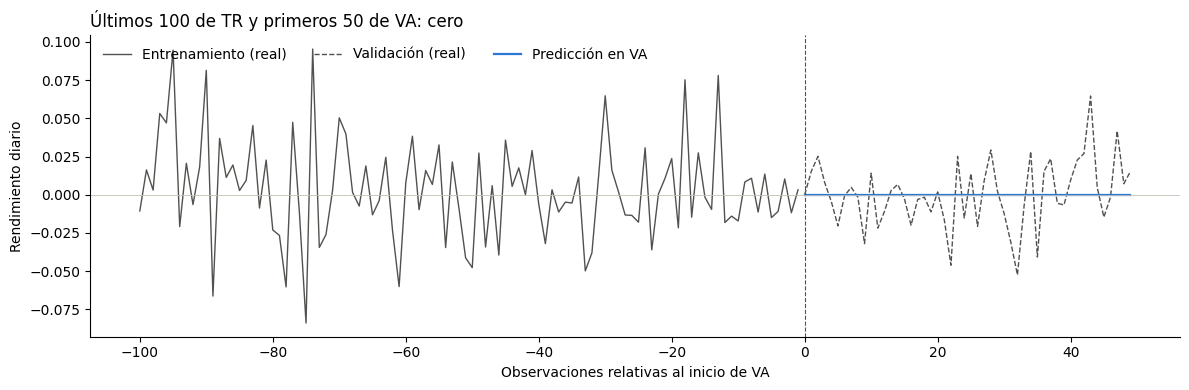

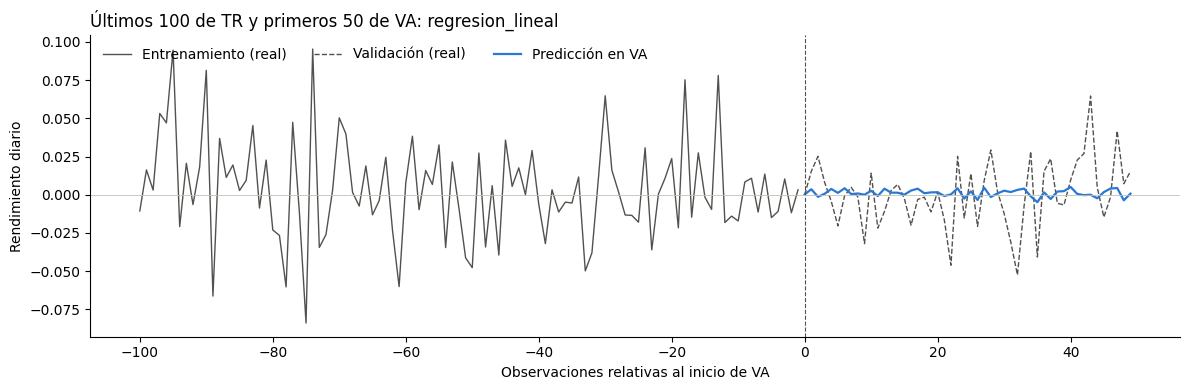

In [14]:
# === 8.1 Gráfica del libro: últimos valores de TR, primeros de VA y predicción ===
def plot_train_val_values(n_tr, n_va, y_train, y_val, y_pred_val, titulo):
    'Equivalente a plot_train_test_values() del libro, usando VA en lugar de test.'
    eje_tr = np.arange(-n_tr, 0)
    eje_va = np.arange(0, n_va)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(eje_tr, y_train[-n_tr:], color='#52514e', lw=1.0, label='Entrenamiento (real)')
    ax.plot(eje_va, y_val[:n_va], color='#52514e', lw=1.0, ls='--', label='Validación (real)')
    ax.plot(eje_va, y_pred_val[:n_va], color='#2a78d6', lw=1.6, label='Predicción en VA')
    ax.axvline(0, color='#52514e', ls='--', lw=0.8)
    ax.axhline(0, color='#c3c2b7', lw=0.6)
    ax.set_xlabel('Observaciones relativas al inicio de VA'); ax.set_ylabel('Rendimiento diario')
    ax.set_title(titulo, loc='left'); ax.legend(frameon=False, ncol=3, loc='upper left')
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    return fig

for m in ['cero', 'regresion_lineal']:
    fig = plot_train_val_values(100, 50, y_tr, y_va, PRED[m]['VA'], f'Últimos 100 de TR y primeros 50 de VA: {m}')
    fig.savefig(DIRS['figuras'] / f'cap7_train_val_{m}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [15]:
# === 8.2 Lectura de resultados, sobreajuste/subajuste y meta para DL ===
va = RESULTADOS_C7[RESULTADOS_C7.conjunto == 'VA'].set_index('modelo')
tr = RESULTADOS_C7[RESULTADOS_C7.conjunto == 'TR'].set_index('modelo')
mejora_rmse = 1 - va.loc['regresion_lineal', 'RMSE'] / va.loc['cero', 'RMSE']
mejora_mae = 1 - va.loc['regresion_lineal', 'MAE'] / va.loc['cero', 'MAE']
print(f'Regresión lineal vs. cero en VA: RMSE {mejora_rmse:+.2%}, MAE {mejora_mae:+.2%} (positivo = la regresión mejora)')

print('\nDiagnóstico de ajuste de la regresión lineal (cap. 7, Overfitting and Underfitting):')
for met in ['RMSE', 'MAE', 'prec_direccional', 'correlacion']:
    print(f'  {met:17s} TR = {tr.loc["regresion_lineal", met]:.6f}   VA = {va.loc["regresion_lineal", met]:.6f}')
cae_corr = tr.loc['regresion_lineal', 'correlacion'] - va.loc['regresion_lineal', 'correlacion']
if va.loc['regresion_lineal', 'RMSE'] >= va.loc['cero', 'RMSE'] and cae_corr > 0.05:
    print('  → Indicio de SOBREAJUSTE: la relación encontrada en TR no se sostiene en VA y no supera al pronóstico cero.')
elif va.loc['regresion_lineal', 'RMSE'] >= va.loc['cero', 'RMSE']:
    print('  → Indicio de SUBAJUSTE / sin información lineal útil: ni en TR ni en VA supera claramente al cero.')
else:
    print('  → La regresión supera al cero en VA; revisar si la mejora es estable en las ventanas del cap. 9.')
print('  Nota: el RMSE también cambia porque la volatilidad de VA es distinta a la de TR; compárenlo contra el cero del mismo conjunto.')

OBLIGATORIAS = ['cero', 'regresion_lineal']
META_DL = {'RMSE_VA_a_superar': float(va.loc[OBLIGATORIAS, 'RMSE'].min()),
           'MAE_VA_a_superar': float(va.loc[OBLIGATORIAS, 'MAE'].min()),
           'mejor_referencia_RMSE': va.loc[OBLIGATORIAS, 'RMSE'].idxmin(),
           'mejor_referencia_MAE': va.loc[OBLIGATORIAS, 'MAE'].idxmin(),
           'RMSE_VA_regresion_lineal': float(va.loc['regresion_lineal', 'RMSE']),
           'MAE_VA_regresion_lineal': float(va.loc['regresion_lineal', 'MAE'])}
with open(DIRS['resultados'] / 'meta_para_dl.json', 'w') as f:
    json.dump(META_DL, f, indent=2)
print('\nPara aportar algo, MLP/LSTM (cap. 8) deben lograr en VA:')
print(f"  RMSE < {META_DL['RMSE_VA_a_superar']:.6f} (mejor referencia: {META_DL['mejor_referencia_RMSE']})")
print(f"  MAE  < {META_DL['MAE_VA_a_superar']:.6f} (mejor referencia: {META_DL['mejor_referencia_MAE']})")

Regresión lineal vs. cero en VA: RMSE +0.34%, MAE -0.33% (positivo = la regresión mejora)

Diagnóstico de ajuste de la regresión lineal (cap. 7, Overfitting and Underfitting):
  RMSE              TR = 0.034892   VA = 0.024258
  MAE               TR = 0.023341   VA = 0.017276
  prec_direccional  TR = 0.526367   VA = 0.502262
  correlacion       TR = 0.118950   VA = 0.072848
  → La regresión supera al cero en VA; revisar si la mejora es estable en las ventanas del cap. 9.
  Nota: el RMSE también cambia porque la volatilidad de VA es distinta a la de TR; compárenlo contra el cero del mismo conjunto.

Para aportar algo, MLP/LSTM (cap. 8) deben lograr en VA:
  RMSE < 0.024258 (mejor referencia: regresion_lineal)
  MAE  < 0.017219 (mejor referencia: cero)


### 8.3 Complemento: los demás modelos del capítulo 7

El protocolo solo exige el pronóstico cero y la regresión lineal. Como el capítulo 7 presenta además SVR, SGD, KNN, árbol de decisión, bosque aleatorio, AdaBoost y XGBoost, aquí se corren **con los hiperparámetros del libro, sin ajustarlos**, sobre los mismos 20 rezagos, el mismo escalador y solo TR/VA. Sirven para ver si algún modelo no lineal clásico ya encuentra algo antes de pasar a redes. Si quieren omitirlos, pongan `MODELOS_CAPITULO_7 = False`.

In [16]:
# === 8.3 Modelos complementarios del capítulo 7 (hiperparámetros del libro) ===
MODELOS_CAPITULO_7 = True

if MODELOS_CAPITULO_7:
    from sklearn.svm import SVR
    from sklearn.linear_model import SGDRegressor
    from sklearn.neighbors import KNeighborsRegressor
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
    complementarios = [
        ('svr', SVR(kernel='rbf', C=1, gamma=0.04, epsilon=0.01), "SVR(kernel='rbf', C=1, gamma=0.04, epsilon=0.01)"),
        ('sgd', SGDRegressor(max_iter=50, tol=1e-3, random_state=SEMILLA), 'SGDRegressor(max_iter=50, tol=1e-3)'),
        ('knn', KNeighborsRegressor(n_neighbors=10), 'KNeighborsRegressor(n_neighbors=10)'),
        ('arbol', DecisionTreeRegressor(random_state=123), 'DecisionTreeRegressor(random_state=123)'),
        ('bosque', RandomForestRegressor(max_depth=20, random_state=123, n_jobs=-1), 'RandomForestRegressor(max_depth=20, random_state=123)'),
        ('adaboost', AdaBoostRegressor(random_state=123), 'AdaBoostRegressor(random_state=123)'),
    ]
    try:
        from xgboost import XGBRegressor
        complementarios.append(('xgboost', XGBRegressor(random_state=123, n_estimators=16, max_depth=12, n_jobs=-1),
                                'XGBRegressor(random_state=123, n_estimators=16, max_depth=12)'))
    except ImportError:
        registrar_evento('cap7 complementarios', 'xgboost no instalado', 'ImportError',
                         'Se omite XGBoost; instalar con pip install xgboost si se desea', 'resto de modelos ejecutados')
    filas_c = []
    for nombre, modelo, conf in complementarios:
        PRED[nombre], f = evaluar_modelo(nombre, modelo, conf, 'complementario_cap7')
        filas_c += f
        print(f'  {nombre:9s} listo')
    RESULTADOS_C7 = pd.concat([RESULTADOS_C7, pd.DataFrame(filas_c)], ignore_index=True)

comparacion_va = (RESULTADOS_C7[RESULTADOS_C7.conjunto == 'VA']
                  .merge(RESULTADOS_C7[RESULTADOS_C7.conjunto == 'TR'][['modelo', 'RMSE', 'prec_direccional']],
                         on='modelo', suffixes=('_VA', '_TR'))
                  .sort_values('RMSE_VA'))
comparacion_va = comparacion_va[['modelo', 'tipo', 'RMSE_TR', 'RMSE_VA', 'MAE', 'prec_direccional_TR',
                                 'prec_direccional_VA', 'correlacion', 'model_bias']].rename(
                                     columns={'MAE': 'MAE_VA', 'correlacion': 'correlacion_VA', 'model_bias': 'model_bias_VA'})
comparacion_va.to_csv(DIRS['resultados'] / 'comparacion_modelos_cap7_VA.csv', index=False)
print('\nOrdenado por RMSE de VA (TR se muestra para detectar sobreajuste: TR muy bajo y VA alto = sobreajuste):')
comparacion_va.round(6)

  svr       listo
  sgd       listo
  knn       listo
  arbol     listo
  bosque    listo
  adaboost  listo
  xgboost   listo

Ordenado por RMSE de VA (TR se muestra para detectar sobreajuste: TR muy bajo y VA alto = sobreajuste):


,modelo,tipo,RMSE_TR,RMSE_VA,MAE_VA,prec_direccional_TR,prec_direccional_VA,correlacion_VA,model_bias_VA
4,sgd,complementario_cap7,0.034959,0.024226,0.017269,0.523948,0.533937,0.087109,2.400000
2,regresion_lineal,referencia,0.034892,0.024258,0.017276,0.526367,0.502262,0.072848,3.018182
1,media_TR,referencia,0.035142,0.024293,0.017250,0.513304,0.511312,NaN,NaN
0,cero,referencia,0.035180,0.024342,0.017219,NaN,NaN,NaN,NaN
7,bosque,complementario_cap7,0.020561,0.024635,0.017702,0.817610,0.477376,-0.011797,2.593496
8,adaboost,complementario_cap7,0.032705,0.025281,0.018542,0.522013,0.522624,0.029716,3.652632
5,knn,complementario_cap7,0.032592,0.025723,0.018586,0.617804,0.479638,-0.014826,1.376344
9,xgboost,complementario_cap7,0.006033,0.027546,0.020796,0.948718,0.457014,-0.060595,1.511364
3,svr,complementario_cap7,0.016830,0.029043,0.020759,0.789066,0.504525,-0.058058,1.221106
6,arbol,complementario_cap7,0.000000,0.036174,0.026602,1.000000,0.490950,0.067428,1.000000


## 9. Exploración: precio, rendimientos, volatilidad histórica y medias móviles

- Volatilidad histórica: desviación estándar **muestral** de los últimos 20 rendimientos diarios, sin anualizar. Solo usa historia hasta $t$; sus primeros valores quedan vacíos (no se rellenan hacia atrás).
- Distancia a SMA20: $\text{cierre}/\text{SMA}_{20} - 1$.
- Las franjas sombreadas marcan los periodos de objetivos de TR, VA y TE.

Primera fecha válida  vol20: 2018-09-12 | SMA20: 2018-09-11 | SMA50: 2018-10-11


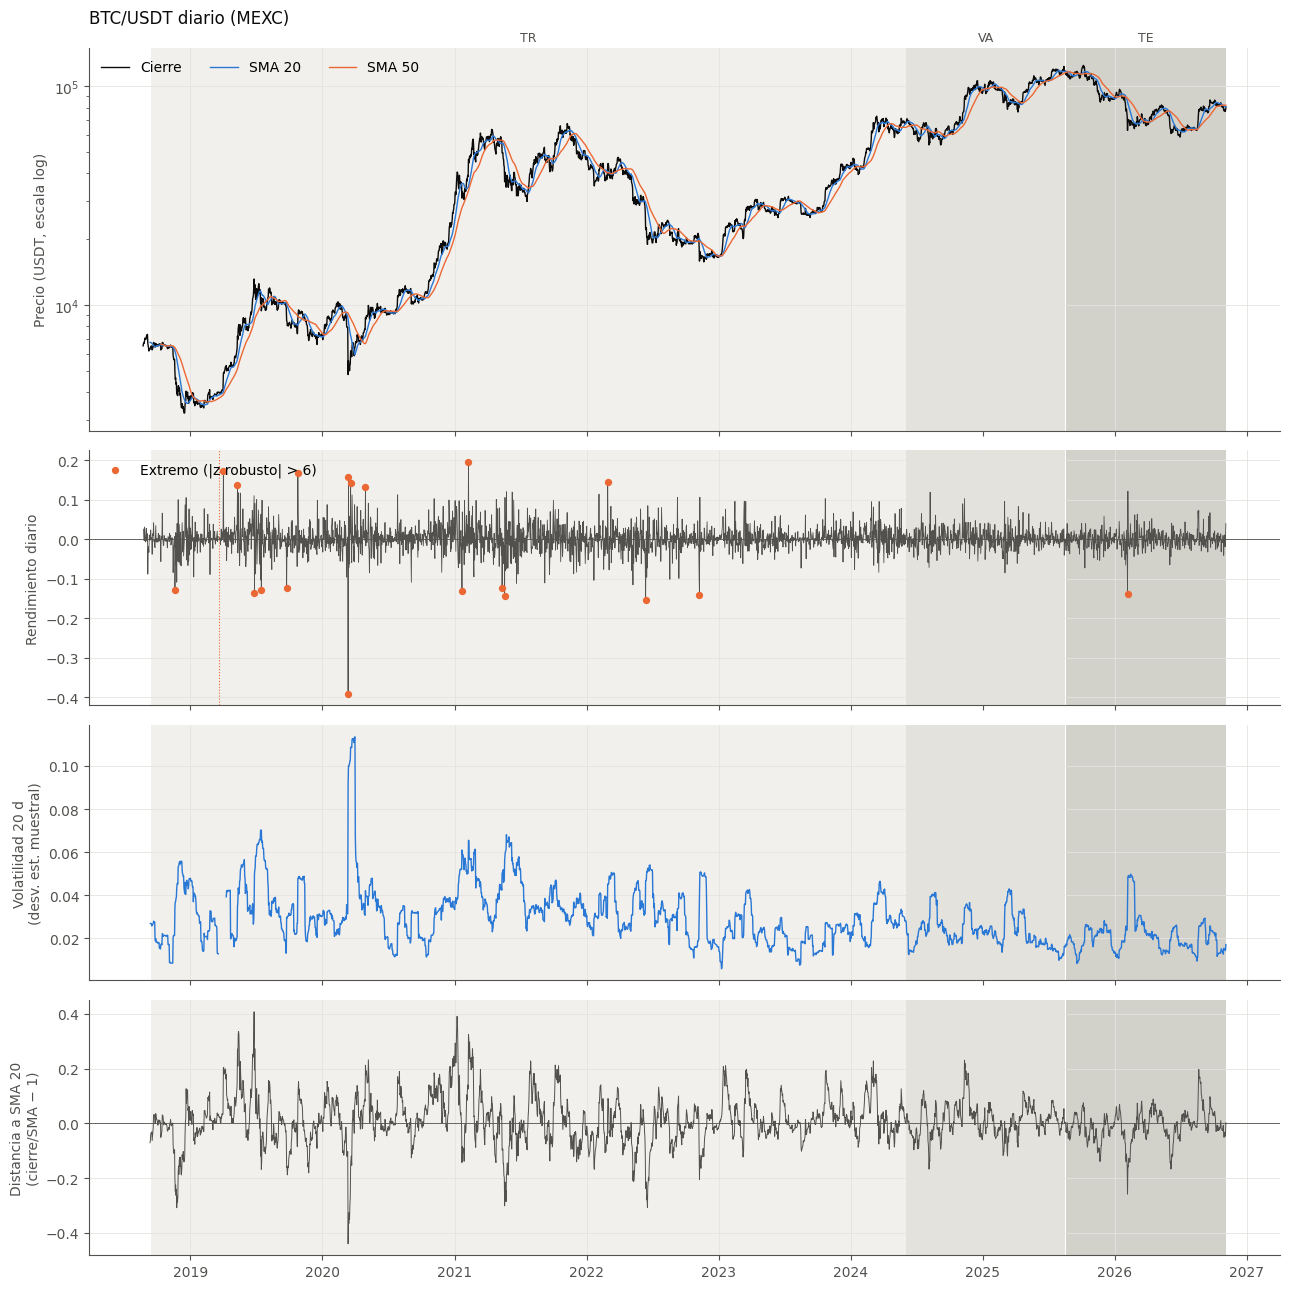

In [17]:
# === 9. Gráficas descriptivas ===
ex = datos[['fecha', 'close']].copy()
ex['ret'] = ex['close'] / ex['close'].shift(1) - 1
ex.loc[ex['fecha'].diff() != UN_DIA, 'ret'] = np.nan            # no mezclar rendimientos que cruzan huecos
ex['vol20'] = ex['ret'].rolling(20, min_periods=20).std(ddof=1)
ex['sma20'] = ex['close'].rolling(20, min_periods=20).mean()
ex['sma50'] = ex['close'].rolling(50, min_periods=50).mean()
ex['dist_sma20'] = ex['close'] / ex['sma20'] - 1
print('Primera fecha válida  vol20:', ex.loc[ex.vol20.notna(), 'fecha'].min().date(),
      '| SMA20:', ex.loc[ex.sma20.notna(), 'fecha'].min().date(),
      '| SMA50:', ex.loc[ex.sma50.notna(), 'fecha'].min().date())

TINTA, TINTA2, REJILLA = '#0b0b0b', '#52514e', '#e4e3df'
AZUL, NARANJA = '#2a78d6', '#eb6834'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': TINTA2,
                     'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
                     'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.6, 'font.size': 10})
TONOS = {'TR': '#f1f0ec', 'VA': '#e3e2dc', 'TE': '#d2d1ca'}

def sombrear(ax, rotular=False):
    for nombre, p in (('TR', TR), ('VA', VA), ('TE', TE)):
        a, b = p.fecha_objetivo.min(), p.fecha_objetivo.max()
        ax.axvspan(a, b, color=TONOS[nombre], zorder=0, lw=0)
        if rotular:
            ax.text(a + (b - a) / 2, 1.01, nombre, transform=ax.get_xaxis_transform(),
                    ha='center', va='bottom', color=TINTA2, fontsize=9)

fig, ax = plt.subplots(4, 1, figsize=(13, 13), sharex=True, gridspec_kw={'height_ratios': [3, 2, 2, 2]})
sombrear(ax[0], rotular=True)
ax[0].plot(ex.fecha, ex.close, color=TINTA, lw=1.0, label='Cierre')
ax[0].plot(ex.fecha, ex.sma20, color=AZUL, lw=1.0, label='SMA 20')
ax[0].plot(ex.fecha, ex.sma50, color=NARANJA, lw=1.0, label='SMA 50')
ax[0].set_yscale('log'); ax[0].set_ylabel(f'Precio ({CONFIG["MONEDA_COTIZADA"]}, escala log)')
ax[0].legend(loc='upper left', frameon=False, ncol=3)
ax[0].set_title(f'{CONFIG["MONEDA_BASE"]}/{CONFIG["MONEDA_COTIZADA"]} diario (MEXC)', loc='left', color=TINTA, pad=18)

sombrear(ax[1])
ax[1].plot(ex.fecha, ex.ret, color=TINTA2, lw=0.6)
if len(EXTREMOS):
    m = ex.fecha.isin(EXTREMOS.fecha)
    ax[1].scatter(ex.fecha[m], ex.ret[m], s=18, color=NARANJA, zorder=3, label='Extremo (|z robusto| > 6)')
    ax[1].legend(loc='upper left', frameon=False)
for f_falt in FALTANTES:
    ax[1].axvline(f_falt, color=NARANJA, lw=0.8, ls=':')
ax[1].axhline(0, color=TINTA2, lw=0.6)
ax[1].set_ylabel('Rendimiento diario')

sombrear(ax[2])
ax[2].plot(ex.fecha, ex.vol20, color=AZUL, lw=1.0)
ax[2].set_ylabel('Volatilidad 20 d\n(desv. est. muestral)')

sombrear(ax[3])
ax[3].plot(ex.fecha, ex.dist_sma20, color=TINTA2, lw=0.7)
ax[3].axhline(0, color=TINTA2, lw=0.6)
ax[3].set_ylabel('Distancia a SMA 20\n(cierre/SMA − 1)')
ax[3].xaxis.set_major_locator(mdates.YearLocator()); ax[3].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout()
fig.savefig(DIRS['figuras'] / 'cap7_precio_rendimientos_volatilidad.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# === 9.1 Faltantes, extremos y cambios de comportamiento (descriptivo) ===
print(f'Días faltantes en calendario continuo: {len(FALTANTES)}', list(FALTANTES.strftime('%Y-%m-%d')[:20]))
print(f'Rendimientos extremos marcados: {len(EXTREMOS)}')
display(EXTREMOS) if 'display' in globals() else print(EXTREMOS)

anual = ex.dropna(subset=['ret']).groupby(ex.fecha.dt.year).agg(
    dias=('ret', 'size'), rend_medio=('ret', 'mean'), desv_est=('ret', 'std'),
    peor_dia=('ret', 'min'), mejor_dia=('ret', 'max'))
anual['rend_acumulado'] = ex.groupby(ex.fecha.dt.year)['close'].agg(lambda s: s.iloc[-1] / s.iloc[0] - 1)
anual.index.name = 'año'
anual.to_csv(DIRS['resultados'] / 'resumen_anual_cap7.csv')
print('\nPeriodos de mayor volatilidad de 20 días (picos):')
print(ex.nlargest(5, 'vol20')[['fecha', 'vol20']].to_string(index=False))
anual.round(4)

Días faltantes en calendario continuo: 1 ['2019-03-20']
Rendimientos extremos marcados: 19
          fecha  rendimiento
88   2018-11-19      -0.1289
221  2019-04-02       0.1725
260  2019-05-11       0.1367
307  2019-06-27      -0.1355
326  2019-07-16      -0.1295
396  2019-09-24      -0.1226
427  2019-10-25       0.1683
566  2020-03-12      -0.3919
567  2020-03-13       0.1567
573  2020-03-19       0.1428
614  2020-04-29       0.1332
881  2021-01-21      -0.1305
899  2021-02-08       0.1953
992  2021-05-12      -0.1239
999  2021-05-19      -0.1451
1284 2022-02-28       0.1451
1389 2022-06-13      -0.1539
1538 2022-11-09      -0.1418
2722 2026-02-05      -0.1400

Periodos de mayor volatilidad de 20 días (picos):
     fecha    vol20
2020-03-30 0.113476
2020-03-31 0.113468
2020-03-27 0.112700
2020-03-24 0.112673
2020-03-26 0.112268


,dias,rend_medio,desv_est,peor_dia,mejor_dia,rend_acumulado
año,,,,,,
2018,130,-0.0038,0.0345,-0.1289,0.1052,-0.4331
2019,363,0.0025,0.0362,-0.1355,0.1725,0.8952
2020,366,0.0046,0.0393,-0.3919,0.1567,3.0160
2021,365,0.0022,0.0424,-0.1451,0.1953,0.5755
2022,365,-0.0022,0.0334,-0.1539,0.1451,-0.6534
2023,365,0.0028,0.0231,-0.0733,0.1025,1.5446
2024,366,0.0026,0.0278,-0.0839,0.1190,1.1181
2025,365,0.0001,0.0218,-0.0854,0.0953,-0.0734
2026,308,-0.0000,0.0233,-0.1400,0.1214,-0.0939


## 10. Estudio técnico descriptivo e hipótesis verificable

**Hipótesis H1 (a verificar en el capítulo 11):** la distancia del cierre respecto de su SMA de 20 cierres al momento $t$ contiene información sobre el rendimiento del día siguiente $y_t$; agregarla a los 20 rezagos reduciría el MAE/RMSE de VA.

**H0:** no aporta información; el error en VA no mejora (o empeora).

Abajo solo se describe la relación **dentro de TR** (correlación y rendimiento medio por quintil de distancia). Esto no es una prueba de capacidad predictiva: la evaluación formal se hará comparando el modelo con y sin el indicador en VA (cap. 11).

In [19]:
# === 10. Descripción en TR de la hipótesis técnica ===
tr_h = TR[['fecha_emision', 'y']].merge(ex[['fecha', 'dist_sma20']], left_on='fecha_emision', right_on='fecha', how='left')
tr_h = tr_h.dropna(subset=['dist_sma20'])          # filas iniciales sin SMA válida se retiran, no se rellenan
pearson = tr_h['dist_sma20'].corr(tr_h['y'])
spearman = tr_h['dist_sma20'].corr(tr_h['y'], method='spearman')
cortes = tr_h['dist_sma20'].quantile([0, .2, .4, .6, .8, 1]).to_numpy().copy()   # cortes calculados solo con TR
cortes[0], cortes[-1] = -np.inf, np.inf
tr_h['quintil'] = pd.cut(tr_h['dist_sma20'], cortes, labels=['Q1 (muy abajo)', 'Q2', 'Q3', 'Q4', 'Q5 (muy arriba)'])
por_q = tr_h.groupby('quintil', observed=True)['y'].agg(n='size', y_media='mean', y_mediana='median',
                                                        frac_positivos=lambda s: (s > 0).mean())
print(f'TR: n = {len(tr_h)}, Pearson = {pearson:+.4f}, Spearman = {spearman:+.4f}')
HIPOTESIS = {'H1': 'dist_sma20_t aporta información sobre y_t; añadirla a los 20 rezagos reduce MAE/RMSE en VA',
             'H0': 'dist_sma20_t no aporta información; el error en VA no mejora',
             'evidencia_descriptiva_TR': {'n': int(len(tr_h)), 'pearson': float(pearson), 'spearman': float(spearman)},
             'prueba_formal': 'Capítulo 11: modelo con rezagos vs. mismo modelo + indicadores, mismas fechas de VA'}
with open(DIRS['resultados'] / 'hipotesis_tecnica.json', 'w') as f:
    json.dump(HIPOTESIS, f, indent=2, ensure_ascii=False)
por_q.round(5)

TR: n = 2067, Pearson = +0.0128, Spearman = +0.0035


,n,y_media,y_mediana,frac_positivos
quintil,,,,
Q1 (muy abajo),414,0.00148,0.00326,0.56039
Q2,413,0.00035,0.00062,0.51574
Q3,413,0.00019,-0.00062,0.48184
Q4,413,0.00125,-0.00014,0.49395
Q5 (muy arriba),414,0.00493,0.00123,0.51449


## 11. Controles finales del avance y resumen

In [20]:
# === 11. Verificación final del capítulo 7 ===
controles = {
    'Datos y predicciones finitos': bool(np.isfinite(X_tr).all() and np.isfinite(X_va).all()
                                         and all(np.isfinite(p).all() for m in PRED.values() for p in m.values())),
    'Objetivo = siguiente día en todos los ejemplos': bool(((ds.fecha_objetivo - ds.fecha_emision) == UN_DIA).all()),
    'Entradas ≤ fecha de emisión': bool((ds.fecha_primer_cierre < ds.fecha_emision).all()),
    'Orden TR < VA < TE por fecha objetivo': bool(TR.fecha_objetivo.max() < VA.fecha_objetivo.min() < VA.fecha_objetivo.max() < TE.fecha_objetivo.min()),
    'Escalador ajustado solo con TR': bool(escalador.n_samples_seen_ == len(TR)),
    'TE sin predicciones en el cap. 7': all('TE' not in m for m in PRED.values()),
    '≥ 1,500 observaciones válidas': bool(len(datos) >= CONFIG['MIN_OBS']),
    'Una sola hora de corte de vela': pd.to_datetime(datos.open_time, unit='ms').dt.strftime('%H:%M').nunique() == 1,
    'Evidencia T4 guardada': any(DIRS['evidencia'].glob('evidencia_t4_*.json')),
    'T4 verificada (requerida para cap. 8)': bool(EVIDENCIA_T4.get('T4_OK')),
}
for k, v in controles.items():
    print(('✔' if v else '✘'), k)

RESUMEN = {'ficha': FICHA, 'particiones': PARTICIONES.astype(str).to_dict('records'),
           'resultados_cap7': RESULTADOS_C7.to_dict('records'), 'meta_para_dl': META_DL,
           'controles': controles, 'versiones': VERSIONES}
with open(DIRS['resultados'] / 'resumen_cap7.json', 'w') as f:
    json.dump(RESUMEN, f, indent=2, ensure_ascii=False, default=str)

print('\nArchivos guardados en Drive:')
for p in sorted(BASE.rglob('*')):
    if p.is_file():
        print('  ', p.relative_to(BASE))

✔ Datos y predicciones finitos
✔ Objetivo = siguiente día en todos los ejemplos
✔ Entradas ≤ fecha de emisión
✔ Orden TR < VA < TE por fecha objetivo
✔ Escalador ajustado solo con TR
✔ TE sin predicciones en el cap. 7
✔ ≥ 1,500 observaciones válidas
✔ Una sola hora de corte de vela
✔ Evidencia T4 guardada
✔ T4 verificada (requerida para cap. 8)

Archivos guardados en Drive:
   bitacora/bitacora_errores.csv
   datos/originales/BTCUSDT_1d_mexc_crudo.csv
   datos/originales/BTCUSDT_1d_mexc_crudo_meta.json
   datos/originales/BTCUSDT_1d_mexc_crudo_meta_respaldo_20261105T142143Z.json
   datos/originales/BTCUSDT_1d_mexc_crudo_respaldo_20261105T142143Z.csv
   datos/procesados/BTCUSDT_1d_ejemplos_ventanas.csv
   datos/procesados/BTCUSDT_1d_procesado.csv
   evidencia_t4/evidencia_t4_20261105T140258Z.json
   evidencia_t4/evidencia_t4_20261105T141707Z.json
   evidencia_t4/evidencia_t4_20261105T141720Z.json
   evidencia_t4/evidencia_t4_20261105T142137Z.json
   evidencia_t4/nvidia_smi_20261105T1402

## 12. Estudio técnico para el aprendizaje


## Análisis técnico descriptivo e hipótesis verificable

### 1. Análisis técnico descriptivo

A partir de los datos históricos de BTC/USDT, se propone analizar el comportamiento del mercado mediante tres elementos:

- **Tendencias:** observar la dirección general de los precios para identificar periodos de crecimiento, disminución o movimientos laterales.
- **Medias móviles:** utilizar medias móviles de diferentes periodos para suavizar las fluctuaciones de los precios e identificar posibles cambios de tendencia.
- **Volatilidad:** analizar la variabilidad de los rendimientos diarios para identificar periodos de mayor o menor incertidumbre en el mercado.

Estos indicadores permiten describir el comportamiento histórico de Bitcoin; sin embargo, observar patrones o tendencias visuales no significa necesariamente que tengan capacidad para predecir movimientos futuros.

### 2. Hipótesis técnica verificable

Se plantea la siguiente hipótesis:

**La distancia entre el precio de BTC/USDT y su media móvil de 20 días podría aportar información adicional para pronosticar el rendimiento del día siguiente.**

Para comprobarlo, se propone incorporar la distancia relativa respecto a la media móvil como una variable explicativa y comparar dos modelos:

- Un modelo de referencia que pronostique un rendimiento igual a cero.
- Un modelo que incorpore la distancia respecto a la media móvil como variable predictora.

La hipótesis se considerará respaldada si el segundo modelo consigue reducir el error de predicción en los datos de validación frente al pronóstico cero. También se deberá comprobar que la mejora se mantiene al evaluar las señales de operación.

### 3. Validación de los datos y modelos

Antes de continuar con el entrenamiento, es necesario comprobar los siguientes aspectos:

- **Alineación temporal:** asegurar que las variables predictoras utilicen únicamente información disponible hasta el momento de realizar cada pronóstico.
- **Partición de datos:** conservar la separación cronológica entre entrenamiento, validación y prueba para evitar utilizar información futura.
- **Escalamiento:** ajustar el escalador únicamente con los datos de entrenamiento y utilizar esa misma transformación para validación y prueba.
- **Modelos de referencia:** conservar el pronóstico cero y la regresión lineal como puntos de comparación para evaluar si los modelos de Deep Learning aportan una mejora real.

### 4. Conclusión y siguiente paso

El análisis técnico permitirá identificar características del mercado que podrían contener información útil para el pronóstico de los rendimientos de BTC/USDT. No obstante, su utilidad deberá demostrarse mediante pruebas cuantitativas y comparaciones con modelos de referencia.

El siguiente paso será incorporar las variables técnicas, evaluar su capacidad predictiva y determinar si los modelos de Deep Learning consiguen reducir el error frente a pronosticar cero, considerando también los costos de operación.

### ¿qué tendría que mejorar DL frente a pronosticar cero?

Los modelos de Deep Learning deberán obtener en validación un RMSE menor a 0.024258 y un MAE menor a 0.017219 para superar las mejores referencias correspondientes. Además, deberán generar señales direccionales más útiles y demostrar que sus resultados se mantienen al considerar los costos de operación, como el spread y el deslizamiento, incluso si se utiliza la opción de cero comisiones de MEXC.